# RANDOM FOREST - MAX DEPTH 10 (GINI)

### Deskripsi Teori & Varian:
* **Algoritma**: Random Forest (Gini)
* **Varian**: Batas Kedalaman Pohon (Max Depth = 10)
* **Konsep**: Secara default, pohon keputusan akan tumbuh sedalam mungkin hingga semua daun murni (berpotensi overfitting). Varian ini membatasi kedalaman maksimal pohon menjadi 10 level. Tujuannya untuk memaksa model agar lebih general (tidak terlalu menghafal data latih) dan lebih cepat dalam komputasi.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Random Forest - Max Depth 10
model = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=10, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: RANDOM FOREST - MAX DEPTH 10")
print("=============================================")
print(f"1. Algoritma        : Random Forest")
print(f"2. Metrik Jarak     : Gini Impurity (Max Depth 10)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: RANDOM FOREST - MAX DEPTH 10
1. Algoritma        : Random Forest
2. Metrik Jarak     : Gini Impurity (Max Depth 10)
3. Akurasi          : 0.8933
4. Precision (Macro): 0.8968
5. Recall (Macro)   : 0.8933
6. F1-Score (Macro) : 0.8931
7. F1-Score (Weighted): 0.8931
8. Waktu Eksekusi   : 0.7297 detik
9. Penggunaan Memori: 0.40 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.86      0.94      0.90       150
   Hoaks (1)       0.93      0.85      0.89       150

    accuracy                           0.89       300
   macro avg       0.90      0.89      0.89       300
weighted avg       0.90      0.89      0.89       300



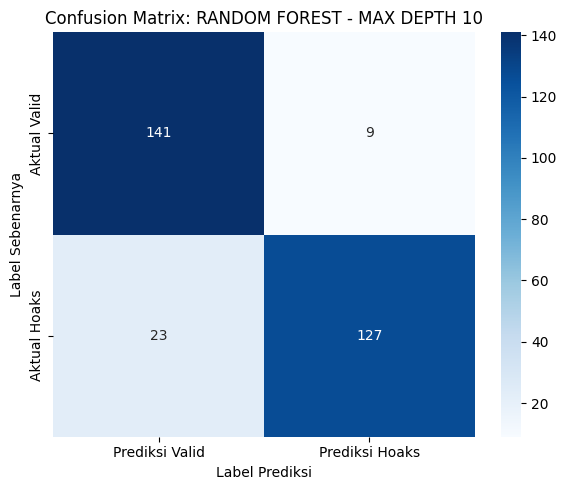

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: RANDOM FOREST - MAX DEPTH 10')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Random Forest (Gini dengan Max Depth 10)

1. **Analisis Performa & Akurasi**:
   * Model Random Forest dengan batasan kedalaman (Max Depth = 10) menghasilkan akurasi sebesar **89.33%** dengan F1-Score 0.8931. 
   * Terjadi penurunan akurasi yang cukup signifikan dibandingkan model Random Forest standar (Gini/Entropy tanpa batas) yang mencapai 91.33%. 

2. **Efek Pembatasan Kedalaman (Underfitting)**:
   * Secara default, pohon keputusan akan tumbuh sangat dalam untuk mempelajari setiap detail pola pada data latih. Dengan membatasi kedalaman maksimal 10 level, kita memaksa model untuk berhenti belajar lebih awal.
   * Akibatnya, model kehilangan kemampuan untuk menangkap kombinasi kata-kata hoaks yang kompleks. Terlihat dari Confusion Matrix, tebakan Hoaks yang benar turun drastis menjadi hanya 127 (sebelumnya 142), sementara ada 23 berita Hoaks yang lolos dianggap Valid. Fenomena ini disebut **Underfitting** (model terlalu sederhana).

3. **Efek Samping Positif (Efisiensi)**:
   * Meskipun akurasinya turun, pembatasan kedalaman membuat waktu eksekusi menjadi lebih cepat (**0.7297 detik** dibanding 0.9907 detik). Memori yang digunakan juga tetap sangat kecil (0.40 MB). 
   * Ini adalah bentuk *trade-off*: kita menukar sedikit akurasi demi kecepatan komputasi dan model yang lebih sederhana (mudah diinterpretasikan).